
=== Fold 1 ===
Pareto fronts:
  Front 1: ['MLP_1', 'MLP_7', 'MLP_27', 'MLP_34', 'MLP_43', 'MLP_52', 'MLP_54', 'MLP_65', 'MLP_66', 'MLP_67', 'MLP_72', 'MLP_73', 'MLP_75', 'MLP_76', 'MLP_77', 'MLP_78', 'MLP_86', 'MLP_87', 'MLP_90', 'MLP_94', 'MLP_96', 'MLP_99']
  Front 2: ['MLP_47', 'MLP_5', 'MLP_63', 'MLP_13', 'MLP_15', 'MLP_23', 'MLP_26', 'MLP_40', 'MLP_49', 'MLP_61', 'MLP_85', 'MLP_88', 'MLP_68', 'MLP_32', 'MLP_11', 'MLP_6', 'MLP_33', 'MLP_38', 'MLP_59', 'MLP_70', 'MLP_93', 'MLP_35', 'MLP_45', 'MLP_62', 'MLP_2', 'MLP_18', 'MLP_19', 'MLP_20', 'MLP_37', 'MLP_39', 'MLP_51', 'MLP_89', 'MLP_98']
  Front 3: ['MLP_82', 'MLP_25', 'MLP_44', 'MLP_83', 'MLP_22', 'MLP_64', 'MLP_8', 'MLP_97', 'MLP_16', 'MLP_21', 'MLP_28', 'MLP_4', 'MLP_60', 'MLP_14', 'MLP_56', 'MLP_30', 'MLP_29', 'MLP_74', 'MLP_3', 'MLP_10', 'MLP_24', 'MLP_31', 'MLP_36', 'MLP_42', 'MLP_46', 'MLP_71', 'MLP_79', 'MLP_80', 'MLP_84', 'MLP_100']
  Front 4: ['MLP_48', 'MLP_41', 'MLP_69', 'MLP_9', 'MLP_50', 'MLP_95', 'MLP_17', 'MLP_53',

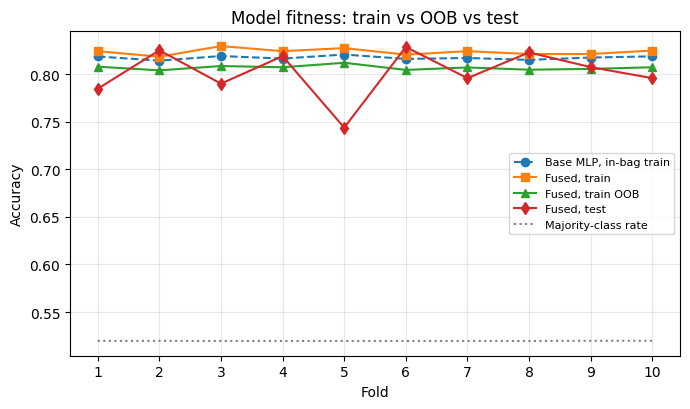

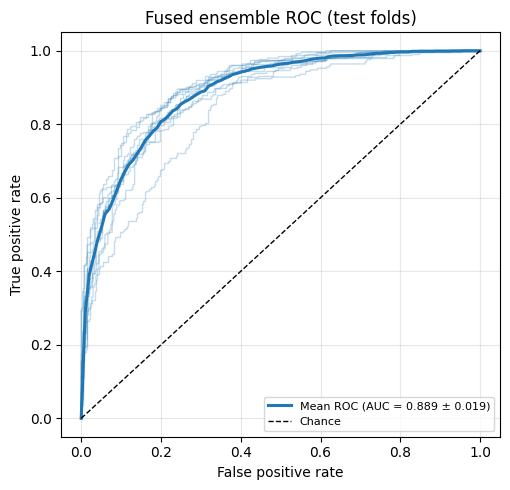

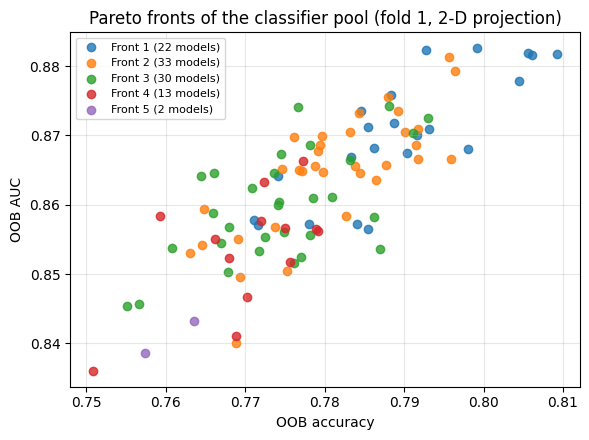

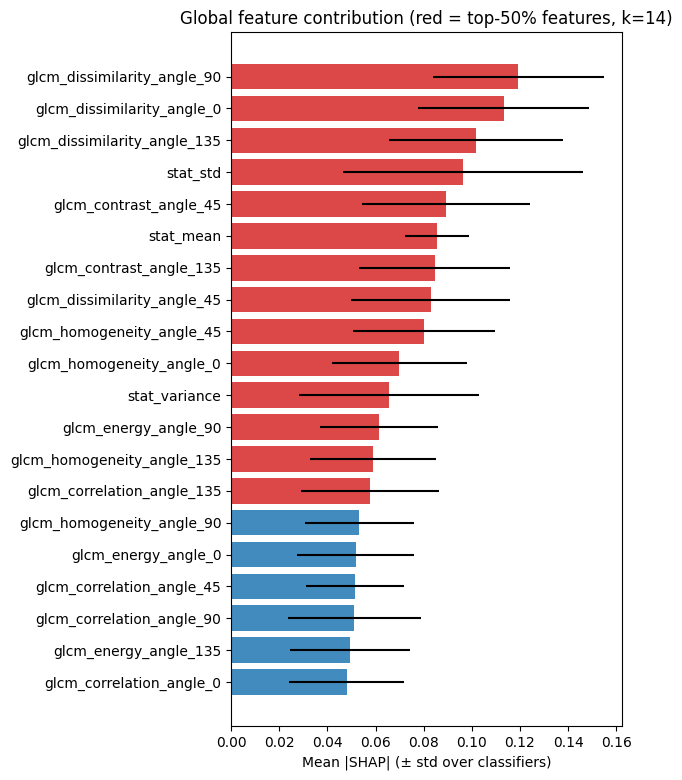

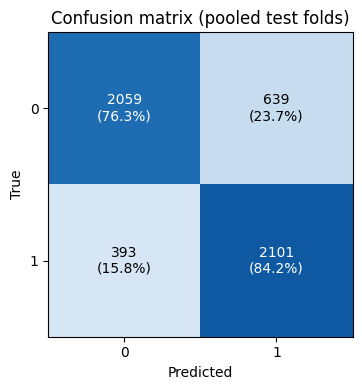

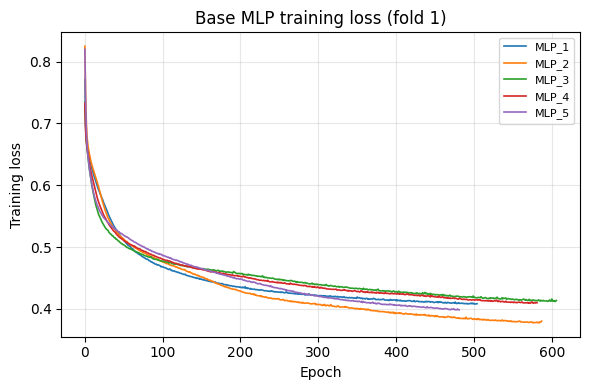

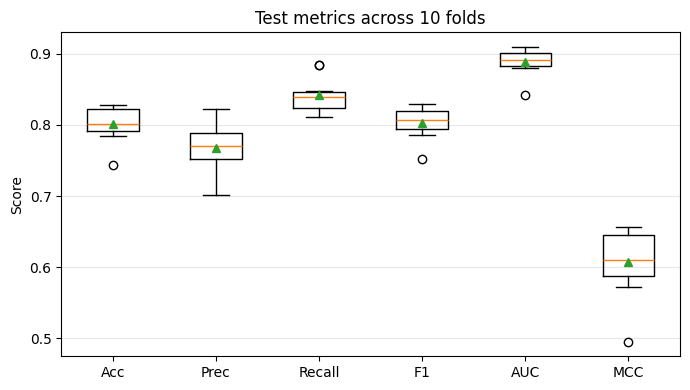


=== Computational cost ===
  python: 3.13.18
  os: Linux-6.6.159+-x86_64-with-glibc2.39
  cpu_model: Intel(R) Xeon(R) CPU @ 2.20GHz
  cpu_logical_cores: 2
  cpu_physical_cores: 1
  ram_total_gb: 13.6
  ram_available_gb: 11.7
  gpu_available: none detected
  gpu_used_by_this_code: no (scikit-learn MLP and SHAP run on the CPU only)
  scikit-learn: 1.6.1
  shap: 0.54.1
  numpy: 2.4.6
  Data: 5192 samples x 29 features | 10 folds x 100 classifiers = 1000 MLPs, each with its own SHAP run
  Total run time: 4658.0 s (77.63 min)
  Per fold: 465.4 ± 6.1 s | per classifier (train + SHAP + evaluation): 4.66 s
                        stage  seconds  percent
                 MLP training  4251.61    91.27
            SHAP attributions   384.97     8.26
               Pareto sorting     1.48     0.03
           Fusion + threshold     0.13     0.00
Predictions / metrics / other    19.85     0.43
  Peak memory (RSS): 400 MB = 2.9% of the 13.6 GB runtime RAM | per-fold probability matrices: 7.89 MB
  

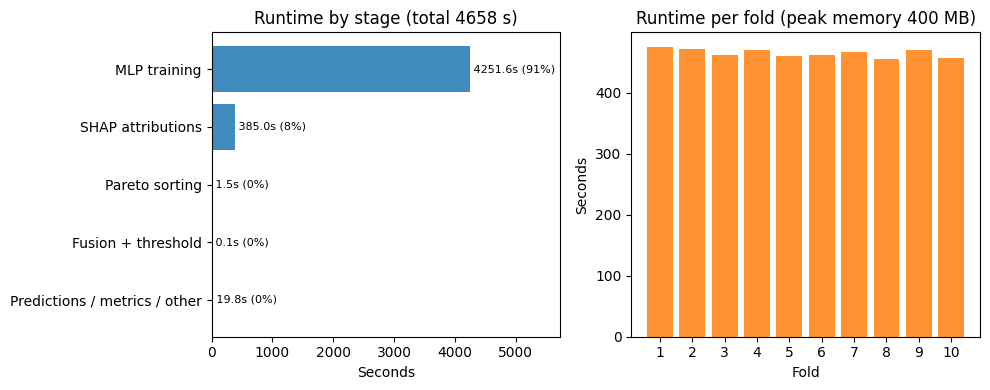


Figures, fold_fit_check.csv, computational_cost.csv and system_info.csv saved in: /content/xcel_outputs


In [5]:
import os
import sys
import time
import platform
import subprocess
import warnings
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve, matthews_corrcoef)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ config
# Robust argument checking: skip flags and connection files ending in .json introduced by the Jupyter/Colab runtime
args = [a for a in sys.argv[1:] if not a.startswith('-') and not a.endswith('.json')]
DATA_PATH = args[0] if len(args) > 0 else r"/content/glcm_statistical_features_anglewise__oral.csv"
LABEL_COL = "label"        # target column; if absent, the last column is used
N_SPLITS = 10
NUM_CLASSIFIERS = 100
TOP_Q = 0.50              # top-q% features (Omega_q): their SHAP contributions become objectives
SHAP_BACKGROUND = 50      # background rows for the SHAP masker
SHAP_EXPLAIN_ROWS = 100   # validation (OOB) rows explained per classifier (speed)
OUTPUT_DIR = "xcel_outputs"   # figures and the per-fold table are saved here
SEED = 20
rng = np.random.default_rng(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------------ data
df = pd.read_csv(DATA_PATH).fillna(0)
if LABEL_COL not in df.columns:
    LABEL_COL = df.columns[-1]
    print(f"No 'label' column found; using last column '{LABEL_COL}' as the target.")
X = df.drop(columns=[LABEL_COL])
le = LabelEncoder()
y = le.fit_transform(df[LABEL_COL])                 # maps any two class values (e.g. 1/2) to 0/1
assert len(np.unique(y)) == 2, "binary target expected"
feature_names = np.array(X.columns)
X = X.to_numpy(dtype=float)

num_features = X.shape[1]
top_k = max(1, int(num_features * TOP_Q))


# ------------------------------------------------------------------ helpers
def dominates(a, b):
    return np.all(a >= b) and np.any(a > b)


def fast_non_dominated_sort(pop):
    n_pop = len(pop)
    S = [[] for _ in range(n_pop)]
    n = np.zeros(n_pop, dtype=int)
    fronts = [[]]
    for p in range(n_pop):
        for q in range(n_pop):
            if p == q:
                continue
            if dominates(pop[p], pop[q]):
                S[p].append(q)
            elif dominates(pop[q], pop[p]):
                n[p] += 1
        if n[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                n[q] -= 1
                if n[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    fronts.pop()
    return fronts


def top_feature_contributions(mean_abs_shap, k):
    """Mean-|SHAP| contributions of the top-q% features (Omega_q), largest first.
    They are stacked as separate objectives (no summing or averaging)."""
    return np.sort(mean_abs_shap)[::-1][:k]


def sens_spec(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return sens, spec


def fit_verdict(train_acc, test_acc, baseline):
    """Rule-of-thumb check: large train-test gap -> overfitting; train accuracy barely above the
    majority-class rate -> underfitting."""
    if train_acc - test_acc > 0.10:
        return "possible OVERFITTING (train-test gap > 0.10)"
    if train_acc <= baseline + 0.05:
        return "possible UNDERFITTING (train accuracy within 0.05 of the majority-class rate)"
    return "reasonable fit"


def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name), dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def system_info():
    """Runtime hardware / software description (what Colab actually gave us)."""
    info = {"python": platform.python_version(), "os": platform.platform()}
    cpu_model = platform.processor()
    try:
        with open("/proc/cpuinfo") as fh:
            for line in fh:
                if line.startswith("model name"):
                    cpu_model = line.split(":", 1)[1].strip()
                    break
    except Exception:
        pass
    info["cpu_model"] = cpu_model or "unknown"
    info["cpu_logical_cores"] = os.cpu_count()
    try:
        import psutil
        info["cpu_physical_cores"] = psutil.cpu_count(logical=False)
        info["ram_total_gb"] = round(psutil.virtual_memory().total / 1e9, 1)
        info["ram_available_gb"] = round(psutil.virtual_memory().available / 1e9, 1)
    except Exception:
        pass
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=10)
        info["gpu_available"] = out.stdout.strip() if (out.returncode == 0 and out.stdout.strip()) else "none detected"
    except Exception:
        info["gpu_available"] = "none detected"
    info["gpu_used_by_this_code"] = "no (scikit-learn MLP and SHAP run on the CPU only)"
    import sklearn
    info["scikit-learn"], info["shap"], info["numpy"] = sklearn.__version__, shap.__version__, np.__version__
    return info


def peak_memory_mb():
    """Peak resident memory of this process (Linux/Colab: ru_maxrss is in KB)."""
    try:
        import resource
        peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return peak / 1024 if sys.platform != "darwin" else peak / 1024 ** 2
    except Exception:
        return float("nan")


# ------------------------------------------------------------------ CV
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_acc, fold_prec, fold_rec, fold_f1, fold_auc, fold_mcc = [], [], [], [], [], []
fit_rows = []                                  # per-fold fitness diagnostics
roc_curves = []                                # (fpr, tpr) of the fused ensemble per fold
all_y_test, all_pred = [], []
all_mean_shap = []                             # mean |SHAP| vector of every classifier
loss_curves, pareto_fold1 = [], None
mean_fpr = np.linspace(0, 1, 101)
stage_time = {"mlp_training": 0.0, "shap": 0.0, "pareto_sort": 0.0, "fusion_threshold": 0.0}
fold_times = []
run_start = time.perf_counter()

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    print(f"\n=== Fold {fold} ===")
    fold_t0 = time.perf_counter()

    # ONE normalization (StandardScaler), fitted on the training fold only
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X[train_idx])
    X_test = scaler.transform(X[test_idx])
    y_train_fold, y_test = y[train_idx], y[test_idx]
    n_train = len(X_train_fold)

    test_probs = []        # test probabilities (used for fusion only)
    objectives = []        # Pareto objectives, built from TRAINING data only
    oob_probs = np.full((NUM_CLASSIFIERS, n_train), np.nan)   # OOB training probs (for the threshold)
    train_probs_full = np.zeros((NUM_CLASSIFIERS, n_train))   # in-sample probs on the whole training fold
    base_train_acc, base_oob_acc = [], []

    for c in range(NUM_CLASSIFIERS):
        # bootstrap sample of the training fold; out-of-bag rows are still training data
        boot_idx = rng.choice(n_train, size=n_train, replace=True)
        oob_idx = np.setdiff1d(np.arange(n_train), boot_idx)
        X_boot, y_boot = X_train_fold[boot_idx], y_train_fold[boot_idx]

        # regularised MLP: L2 weight penalty (alpha) against overfitting, and enough iterations
        # to converge (against underfitting). Validation-based early stopping is not used: on
        # small datasets it stops after ~10-20 epochs and the network underfits badly.
        model = MLPClassifier(hidden_layer_sizes=(10,), activation="relu", solver="adam",
                              alpha=1e-2, max_iter=1000, random_state=c)
        _t = time.perf_counter()
        model.fit(X_boot, y_boot)
        stage_time["mlp_training"] += time.perf_counter() - _t
        if fold == 1 and c < 5:
            loss_curves.append(model.loss_curve_)

        # training-side evaluation (OOB rows; fall back to the full training fold)
        if len(oob_idx) > 0 and len(np.unique(y_train_fold[oob_idx])) == 2:
            X_eval, y_eval = X_train_fold[oob_idx], y_train_fold[oob_idx]
        else:
            X_eval, y_eval = X_train_fold, y_train_fold
        if len(oob_idx) > 0:
            oob_probs[c, oob_idx] = model.predict_proba(X_train_fold[oob_idx])[:, 1]
        train_probs_full[c] = model.predict_proba(X_train_fold)[:, 1]
        eval_prob = model.predict_proba(X_eval)[:, 1]
        eval_pred = (eval_prob >= 0.5).astype(int)
        acc = accuracy_score(y_eval, eval_pred)
        auc = roc_auc_score(y_eval, eval_prob)
        sens, spec = sens_spec(y_eval, eval_pred)
        base_train_acc.append(accuracy_score(y_boot, model.predict(X_boot)))   # in-bag (seen) data
        base_oob_acc.append(acc)                                               # unseen OOB data

        # Shapley attributions on the validation (OOB) rows H_train \ H_boot
        def predict_fn(data, _m=model):
            return _m.predict_proba(data)[:, 1]

        _t = time.perf_counter()
        background = shap.sample(X_boot, min(SHAP_BACKGROUND, n_train), random_state=c)
        explain_rows = X_eval[rng.choice(len(X_eval), size=min(SHAP_EXPLAIN_ROWS, len(X_eval)), replace=False)]
        if num_features <= 10:      # few features: exact Shapley values (2^d evaluations per row)
            explainer = shap.explainers.Exact(predict_fn, background)
            shap_values = explainer(explain_rows, max_evals=2 ** num_features)
        else:                       # many features: Permutation SHAP approximation
            explainer = shap.explainers.Permutation(predict_fn, background)
            shap_values = explainer(explain_rows, max_evals=2 * num_features + 1)
        mean_shap = np.mean(np.abs(shap_values.values), axis=0)
        stage_time["shap"] += time.perf_counter() - _t
        all_mean_shap.append(mean_shap)
        top_contrib = top_feature_contributions(mean_shap, top_k)

# #EDIT_maybe!! here No phi i.e. No eqution 7
#         # row of the decision matrix A: [Acc, Sens, Spec, AUC, contrib_1, ..., contrib_k]
#         objectives.append(np.concatenate([[acc, sens, spec, auc], top_contrib]))

        ###EDIT STARTED ( added the eqn 7 implementation)
        phi = top_contrib.sum() / mean_shap.sum()
        objectives.append([acc, sens, spec, auc, phi])   # N x 5
        ## edit ENDS

        test_probs.append(model.predict_proba(X_test)[:, 1])

    objectives = np.array(objectives)
    test_probs = np.array(test_probs)                    # (n_classifiers, n_test)

    # Pareto fronts and weights from training-based objectives
    _t = time.perf_counter()
    fronts = fast_non_dominated_sort(objectives)
    stage_time["pareto_sort"] += time.perf_counter() - _t
    print("Pareto fronts:")
    for i, f in enumerate(fronts):
        print(f"  Front {i + 1}: {[f'MLP_{k + 1}' for k in f]}")
    if fold == 1:
        pareto_fold1 = (objectives[:, 0].copy(), objectives[:, 3].copy(), [list(f) for f in fronts])

    _t = time.perf_counter()
    # front weight w_k = 2(K-k+1) / (K(K+1));  classifier weight alpha_i = w_k / |P_k|
    K = len(fronts)
    clf_w = np.zeros(NUM_CLASSIFIERS)
    front_w = []
    for k, f in enumerate(fronts, start=1):
        w_k = 2 * (K - k + 1) / (K * (K + 1))
        front_w.append(w_k)
        clf_w[f] = w_k / len(f)
    print("Normalized front weights:", np.round(front_w, 4))   # sums to 1; so does clf_w

    fused_test_prob = clf_w @ test_probs

    # Youden's J threshold chosen on TRAINING data only, then applied to the test fold.
    # Each training sample is fused using only the classifiers for which it was out-of-bag,
    # with the same front-based weights, so no classifier scores a row it was trained on.
    valid = ~np.isnan(oob_probs)
    w_mat = clf_w[:, None] * valid
    denom = w_mat.sum(axis=0)
    has_oob = denom > 0
    fused_train_prob = (np.nan_to_num(oob_probs) * w_mat).sum(axis=0)[has_oob] / denom[has_oob]
    fpr, tpr, thr = roc_curve(y_train_fold[has_oob], fused_train_prob)
    opt_thr = thr[np.argmax(tpr - fpr)]
    print("Optimal threshold (from training OOB):", opt_thr)
    pred = (fused_test_prob >= opt_thr).astype(int)
    stage_time["fusion_threshold"] += time.perf_counter() - _t

    fold_acc.append(accuracy_score(y_test, pred))
    fold_prec.append(precision_score(y_test, pred, zero_division=0))
    fold_rec.append(recall_score(y_test, pred, zero_division=0))
    fold_f1.append(f1_score(y_test, pred, zero_division=0))
    fold_auc.append(roc_auc_score(y_test, fused_test_prob))
    fold_mcc.append(matthews_corrcoef(y_test, pred))
    all_y_test.append(y_test)
    all_pred.append(pred)
    f_t, t_t, _ = roc_curve(y_test, fused_test_prob)
    roc_curves.append((f_t, t_t))

    # ---- fitness check: training vs OOB vs test accuracy ----
    fused_train_acc = accuracy_score(y_train_fold, (clf_w @ train_probs_full >= opt_thr).astype(int))
    fused_oob_acc = accuracy_score(y_train_fold[has_oob], (fused_train_prob >= opt_thr).astype(int))
    baseline = np.bincount(y_train_fold).max() / n_train
    row = dict(fold=fold,
               base_train_acc=np.mean(base_train_acc), base_oob_acc=np.mean(base_oob_acc),
               fused_train_acc=fused_train_acc, fused_oob_acc=fused_oob_acc,
               test_acc=fold_acc[-1], majority_baseline=baseline)
    fit_rows.append(row)
    print("Fit check (accuracy):")
    print(f"  base MLPs   : in-bag train {row['base_train_acc']:.4f} | OOB (unseen) {row['base_oob_acc']:.4f}")
    print(f"  fused model : train {fused_train_acc:.4f} | train-OOB {fused_oob_acc:.4f} | "
          f"test {fold_acc[-1]:.4f} | majority baseline {baseline:.4f}")
    print(f"  train-test gap {fused_train_acc - fold_acc[-1]:+.4f}  ->  "
          f"{fit_verdict(fused_train_acc, fold_acc[-1], baseline)}")
    fold_times.append(time.perf_counter() - fold_t0)

# ------------------------------------------------------------------ results
print("\n=== Average Results Across Folds ===")
for name, vals in [("Accuracy", fold_acc), ("Precision", fold_prec), ("Recall", fold_rec),
                   ("F1-score", fold_f1), ("ROC AUC", fold_auc), ("MCC", fold_mcc)]:
    print(f"{name}: {np.mean(vals):.4f} ± {np.std(vals):.4f}")

fit_df = pd.DataFrame(fit_rows)
fit_df.to_csv(os.path.join(OUTPUT_DIR, "fold_fit_check.csv"), index=False)
m = fit_df.drop(columns="fold").mean()
print("\n=== Fit check, averaged over folds (accuracy) ===")
print(fit_df.drop(columns="fold").agg(["mean", "std"]).round(4).T.to_string())
print(f"Verdict: {fit_verdict(m['fused_train_acc'], m['test_acc'], m['majority_baseline'])}")

# ------------------------------------------------------------------ figures
folds = fit_df["fold"].to_numpy()

# 1) train vs OOB vs test accuracy per fold (over/underfitting check)
plt.figure(figsize=(7, 4.2))
plt.plot(folds, fit_df["base_train_acc"], "o--", label="Base MLP, in-bag train")
plt.plot(folds, fit_df["fused_train_acc"], "s-", label="Fused, train")
plt.plot(folds, fit_df["fused_oob_acc"], "^-", label="Fused, train OOB")
plt.plot(folds, fit_df["test_acc"], "d-", label="Fused, test")
plt.plot(folds, fit_df["majority_baseline"], ":", color="gray", label="Majority-class rate")
plt.xticks(folds); plt.xlabel("Fold"); plt.ylabel("Accuracy"); plt.title("Model fitness: train vs OOB vs test")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
save_fig("fig1_fitness_train_vs_test.png")

# 2) ROC curves of the fused ensemble on the test folds
plt.figure(figsize=(5.2, 5))
tprs = []
for f_t, t_t in roc_curves:
    plt.plot(f_t, t_t, color="tab:blue", alpha=0.25, lw=1)
    tp_i = np.interp(mean_fpr, f_t, t_t); tp_i[0] = 0.0; tprs.append(tp_i)
mean_tpr = np.mean(tprs, axis=0); mean_tpr[-1] = 1.0
plt.plot(mean_fpr, mean_tpr, color="tab:blue", lw=2.2,
         label=f"Mean ROC (AUC = {np.mean(fold_auc):.3f} ± {np.std(fold_auc):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Fused ensemble ROC (test folds)")
plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=0.3)
save_fig("fig2_roc_curves.png")

# 3) Pareto fronts (fold 1), projected on accuracy vs AUC
acc_o, auc_o, fr = pareto_fold1
plt.figure(figsize=(6, 4.5))
for k, f in enumerate(fr, start=1):
    plt.scatter(np.array(acc_o)[f], np.array(auc_o)[f], s=36, alpha=0.8, label=f"Front {k} ({len(f)} models)")
plt.xlabel("OOB accuracy"); plt.ylabel("OOB AUC")
plt.title("Pareto fronts of the classifier pool (fold 1, 2-D projection)")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
save_fig("fig3_pareto_fronts_fold1.png")

# 4) global SHAP importance (mean |SHAP| over all classifiers and folds)
shap_arr = np.array(all_mean_shap)
g_mean, g_std = shap_arr.mean(axis=0), shap_arr.std(axis=0)
order = np.argsort(g_mean)[::-1]
show = order[:min(20, num_features)]
colors = ["tab:red" if r < top_k else "tab:blue" for r in range(len(show))]
plt.figure(figsize=(6.5, 0.32 * len(show) + 1.5))
plt.barh(range(len(show))[::-1], g_mean[show], xerr=g_std[show], color=colors, alpha=0.85)
plt.yticks(range(len(show))[::-1], feature_names[show])
plt.xlabel("Mean |SHAP| (± std over classifiers)")
plt.title(f"Global feature contribution (red = top-{TOP_Q:.0%} features, k={top_k})")
save_fig("fig4_shap_feature_importance.png")

# 5) confusion matrix, all test folds pooled (row-normalised)
cm = confusion_matrix(np.concatenate(all_y_test), np.concatenate(all_pred), labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(4.4, 4))
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.1%})", ha="center", va="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black")
cls = le.classes_.astype(str)
plt.xticks([0, 1], cls); plt.yticks([0, 1], cls)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (pooled test folds)")
save_fig("fig5_confusion_matrix.png")

# 6) MLP training loss curves (fold 1, first 5 classifiers): convergence / underfitting check
plt.figure(figsize=(6, 4))
for i, lc in enumerate(loss_curves):
    plt.plot(lc, lw=1.2, label=f"MLP_{i + 1}")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title("Base MLP training loss (fold 1)")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
save_fig("fig6_mlp_loss_curves.png")

# 7) metric spread across folds
plt.figure(figsize=(7, 4))
data = [fold_acc, fold_prec, fold_rec, fold_f1, fold_auc, fold_mcc]
plt.boxplot(data, labels=["Acc", "Prec", "Recall", "F1", "AUC", "MCC"], showmeans=True)
plt.ylabel("Score"); plt.title(f"Test metrics across {N_SPLITS} folds"); plt.grid(alpha=0.3, axis="y")
save_fig("fig7_metric_boxplot.png")

# ------------------------------------------------------------------ computational cost
total_time = time.perf_counter() - run_start
n_models = N_SPLITS * NUM_CLASSIFIERS
other = max(total_time - sum(stage_time.values()), 0.0)
stages = {"MLP training": stage_time["mlp_training"], "SHAP attributions": stage_time["shap"],
          "Pareto sorting": stage_time["pareto_sort"], "Fusion + threshold": stage_time["fusion_threshold"],
          "Predictions / metrics / other": other}
cost_df = pd.DataFrame({"stage": list(stages), "seconds": list(stages.values())})
cost_df["percent"] = 100 * cost_df["seconds"] / total_time
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)
sysinfo = system_info()
pd.DataFrame(list(sysinfo.items()), columns=["item", "value"]).to_csv(
    os.path.join(OUTPUT_DIR, "system_info.csv"), index=False)
peak_mb = peak_memory_mb()
arrays_mb = (oob_probs.nbytes + train_probs_full.nbytes + test_probs.nbytes) / 1e6

print("\n=== Computational cost ===")
for k_, v_ in sysinfo.items():
    print(f"  {k_}: {v_}")
print(f"  Data: {len(y)} samples x {num_features} features | {N_SPLITS} folds x {NUM_CLASSIFIERS} classifiers "
      f"= {n_models} MLPs, each with its own SHAP run")
print(f"  Total run time: {total_time:.1f} s ({total_time / 60:.2f} min)")
print(f"  Per fold: {np.mean(fold_times):.1f} ± {np.std(fold_times):.1f} s | "
      f"per classifier (train + SHAP + evaluation): {total_time / n_models:.2f} s")
print(cost_df.round(2).to_string(index=False))
mem_line = f"  Peak memory (RSS): {peak_mb:.0f} MB"
if "ram_total_gb" in sysinfo:
    mem_line += f" = {peak_mb / 1024 / sysinfo['ram_total_gb']:.1%} of the {sysinfo['ram_total_gb']} GB runtime RAM"
print(mem_line + f" | per-fold probability matrices: {arrays_mb:.2f} MB")
print("  Scaling: run time grows ~linearly with N_SPLITS x NUM_CLASSIFIERS; the Pareto sort is O(M*N^2) "
      "per fold; SHAP cost grows with the number of features (Exact: 2^d, Permutation: ~d evaluations per row).")

# 8) runtime breakdown
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].barh(cost_df["stage"][::-1], cost_df["seconds"][::-1], color="tab:blue", alpha=0.85)
for i_, (sec_, pct_) in enumerate(zip(cost_df["seconds"][::-1], cost_df["percent"][::-1])):
    ax[0].text(sec_, i_, f" {sec_:.1f}s ({pct_:.0f}%)", va="center", fontsize=8)
ax[0].set_xlabel("Seconds"); ax[0].set_title(f"Runtime by stage (total {total_time:.0f} s)")
ax[0].set_xlim(0, cost_df["seconds"].max() * 1.35)
ax[1].bar(range(1, len(fold_times) + 1), fold_times, color="tab:orange", alpha=0.85)
ax[1].set_xticks(range(1, len(fold_times) + 1)); ax[1].set_xlabel("Fold"); ax[1].set_ylabel("Seconds")
ax[1].set_title(f"Runtime per fold (peak memory {peak_mb:.0f} MB)")
save_fig("fig8_runtime_breakdown.png")

print(f"\nFigures, fold_fit_check.csv, computational_cost.csv and system_info.csv saved in: {os.path.abspath(OUTPUT_DIR)}")

In [ ]:
#to download the results folder as zip


# from google.colab import files

# # 1. Zip the folder (-r includes all subdirectories recursively)
# !zip -r /content/xcel_outputs.zip /content/xcel_outputs

# # 2. Download the resulting zip file
# files.download('/content/xcel_outputs.zip')

  adding: content/xcel_outputs/ (stored 0%)
  adding: content/xcel_outputs/fig7_metric_boxplot.png (deflated 22%)
  adding: content/xcel_outputs/system_info.csv (deflated 27%)
  adding: content/xcel_outputs/fig2_roc_curves.png (deflated 13%)
  adding: content/xcel_outputs/fig4_shap_feature_importance.png (deflated 29%)
  adding: content/xcel_outputs/fig1_fitness_train_vs_test.png (deflated 13%)
  adding: content/xcel_outputs/computational_cost.csv (deflated 27%)
  adding: content/xcel_outputs/fig8_runtime_breakdown.png (deflated 21%)
  adding: content/xcel_outputs/fig5_confusion_matrix.png (deflated 14%)
  adding: content/xcel_outputs/fig3_pareto_fronts_fold1.png (deflated 10%)
  adding: content/xcel_outputs/fold_fit_check.csv (deflated 63%)
  adding: content/xcel_outputs/fig6_mlp_loss_curves.png (deflated 12%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>